# LA2: NEON Surface-Water Nitrate Forecasting

 
**Assigned sites:** LECO, LEWI, MCDI  
**Data product:** NEON Nitrate in Surface Water, DP1.20033.001  
**Target:** `surfWaterNitrateMean` aggregated into a 30-minute nitrate mean (µmol/L).  
**Forecast horizons:** 24 hours and 7 days ahead.

This notebook reads the original `NSW_15_minute` CSV files, filters the NEON quality flag, removes duplicate site/timestamp records, aggregates to 30-minute bins, builds lag/calendar predictors, implements three assigned regression models, compares them against simple baselines, and records model metrics and execution-time/scalability measurements.

**Forecast design:** each row is indexed by the end of a completed 30-minute interval. Only current and historical predictors are used. A target is kept only when an accepted measurement exists exactly 24 hours or 7 days later; no future labels are interpolated. The split is chronological by site, and training labels must also occur before the site's test cutoff.

**Important:** the PDF includes local reference results for the assigned models. Run this notebook to regenerate model metrics and timings on your machine. Spark performs ETL and feature construction; the selected Python estimators run on bounded samples, so their fit/predict seconds are not Spark MLlib timings.

## 1. Environment and project paths

Use a local Spark installation (PySpark 3.5+ recommended), pandas, matplotlib, scikit-learn and the additional model libraries listed in requirements.txt. Start Jupyter from the extracted person folder or adjust the root path in the first code cell.

In [2]:
from pathlib import Path
import time, math, json, os
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import warnings


PERSON = "Jayavardhan"
SITE_IDS = ['LECO', 'LEWI', 'MCDI']

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "dataset" / "raw").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not find dataset/raw. Start Jupyter from the extracted person folder, "
        "or update PROJECT_ROOT to point at that folder."
    )

PROJECT_ROOT = find_project_root()
RAW_DIR = PROJECT_ROOT / "dataset" / "raw"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR = OUTPUT_DIR / "tables"
for folder in (OUTPUT_DIR, FIGURE_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

spark = (
    SparkSession.builder
    .appName(f"LA2_{PERSON}_NEON_Nitrate_Forecasting")
    .config("spark.sql.session.timeZone", "UTC")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print("Project root:", PROJECT_ROOT)
print("Selected sites:", SITE_IDS)
print("Spark version:", spark.version)


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/25 11:57:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Project root: /home/vishnu/Downloads/BDA_LA2/person3_updated_LA2
Selected sites: ['LECO', 'LEWI', 'MCDI']
Spark version: 4.2.0


## 2. Load the original dataset and audit quality flags

Only files named `*NSW_15_minute*.csv` are used as measurement inputs. Other metadata files are included to document the source but are not model rows.

In [3]:
# Load only the original NEON NSW_15_minute measurement tables for the assigned sites.
site_paths = [str(RAW_DIR / site) for site in SITE_IDS]
raw = (
    spark.read
    .option("header", "true")
    .option("inferSchema", "false")
    .option("recursiveFileLookup", "true")
    .option("pathGlobFilter", "*NSW_15_minute*.csv")
    .csv(site_paths)
    .withColumn("source_path", F.input_file_name())
    .withColumn("siteID", F.regexp_extract(F.col("source_path"), r"/raw/([A-Z]{4})/", 1))
)
raw_count = raw.count()
print(f"Original measurement rows loaded: {raw_count:,}")
raw.printSchema()
raw.show(5, truncate=False)

# Quality-flag audit BEFORE filtering. NEON defines finalQF=0 as pass and finalQF=1 as fail.
quality_audit = (
    raw.withColumn("finalQF_int", F.col("finalQF").cast("int"))
       .groupBy("siteID", "finalQF_int")
       .agg(F.count(F.lit(1)).alias("row_count"))
       .orderBy("siteID", "finalQF_int")
)
quality_audit_pd = quality_audit.toPandas()
quality_audit_pd.to_csv(TABLE_DIR / "quality_flag_audit.csv", index=False)
display(quality_audit_pd)


Original measurement rows loaded: 783,936
root
 |-- startDateTime: string (nullable = true)
 |-- endDateTime: string (nullable = true)
 |-- surfWaterNitrateMean: string (nullable = true)
 |-- surfWaterNitrateMinimum: string (nullable = true)
 |-- surfWaterNitrateMaximum: string (nullable = true)
 |-- surfWaterNitrateVariance: string (nullable = true)
 |-- surfWaterNitrateNumPts: string (nullable = true)
 |-- surfWaterNitrateExpUncert: string (nullable = true)
 |-- surfWaterNitrateStdErMean: string (nullable = true)
 |-- finalQF: string (nullable = true)
 |-- source_path: string (nullable = false)
 |-- siteID: string (nullable = false)

+--------------------+--------------------+--------------------+-----------------------+-----------------------+------------------------+----------------------+-------------------------+-------------------------+-------+----------------------------------------------------------------------------------------------------------------------------------------

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

,siteID,finalQF_int,row_count
0,LECO,0,180005
1,LECO,1,83995
2,LEWI,0,209495
3,LEWI,1,50473
4,MCDI,0,192664
5,MCDI,1,67304


## 3. Preprocessing and 30-minute aggregation

NEON's nitrate product is published as 15-minute averages. This study creates 30-minute means from valid 15-minute observations. A 30-minute bin with one accepted source observation is retained and its `valid_15min_count` is kept as a completeness feature; this choice is auditable in the saved data.

In [4]:
# Parse timestamps and numeric fields. Keep nonnegative nitrate observations with finalQF=0.
parsed = (
    raw
    .withColumn("start_ts", F.to_timestamp("startDateTime"))
    .withColumn("end_ts", F.to_timestamp("endDateTime"))
    .withColumn("nitrate", F.col("surfWaterNitrateMean").cast("double"))
    .withColumn("nitrate_min_source", F.col("surfWaterNitrateMinimum").cast("double"))
    .withColumn("nitrate_max_source", F.col("surfWaterNitrateMaximum").cast("double"))
    .withColumn("expanded_uncertainty", F.col("surfWaterNitrateExpUncert").cast("double"))
    .withColumn("standard_error", F.col("surfWaterNitrateStdErMean").cast("double"))
    .withColumn("finalQF_int", F.col("finalQF").cast("int"))
)
quality_filtered = parsed.filter(
    (F.col("siteID").isin(SITE_IDS))
    & F.col("start_ts").isNotNull()
    & F.col("nitrate").isNotNull()
    & (F.col("nitrate") >= 0)
    & (F.col("finalQF_int") == 0)
)

# Remove duplicate site/timestamp rows after applying the quality rule so that a flagged duplicate
# cannot displace an accepted record. Retain one deterministic source path per site/timestamp.
dedup_window = Window.partitionBy("siteID", "start_ts").orderBy(F.col("source_path"))
clean_15m = (
    quality_filtered
    .withColumn("_duplicate_rank", F.row_number().over(dedup_window))
    .filter(F.col("_duplicate_rank") == 1)
    .drop("_duplicate_rank")
    .cache()
)
print(f"Accepted, deduplicated 15-minute observations: {clean_15m.count():,}")

# Aggregate 15-minute means into non-overlapping 30-minute bins. The timestamp used below is the
# END of each 30-minute bin, so a prediction made at time t uses only completed intervals <= t.
with_bins = clean_15m.withColumn("bin", F.window(F.col("start_ts"), "30 minutes"))
aggregated = (
    with_bins.groupBy("siteID", "bin")
    .agg(
        F.avg("nitrate").alias("nitrate_mean"),
        F.min("nitrate_min_source").alias("nitrate_min"),
        F.max("nitrate_max_source").alias("nitrate_max"),
        F.avg("expanded_uncertainty").alias("uncertainty_mean"),
        F.avg("standard_error").alias("std_error_mean"),
        F.count("nitrate").alias("valid_15min_count"),
    )
    .select("siteID", F.col("bin.end").alias("time"), "nitrate_mean", "nitrate_min",
            "nitrate_max", "uncertainty_mean", "std_error_mean", "valid_15min_count")
    .cache()
)
print(f"Available 30-minute intervals: {aggregated.count():,}")
aggregated.orderBy("siteID", "time").show(10, truncate=False)


Accepted, deduplicated 15-minute observations: 580,016


Available 30-minute intervals: 294,626
+------+-------------------+------------+-----------+-----------+------------------+--------------+-----------------+
|siteID|time               |nitrate_mean|nitrate_min|nitrate_max|uncertainty_mean  |std_error_mean|valid_15min_count|
+------+-------------------+------------+-----------+-----------+------------------+--------------+-----------------+
|LECO  |2019-01-22 13:30:00|21.35       |21.3       |21.4       |1.42              |0.01          |2                |
|LECO  |2019-01-22 14:00:00|21.25       |21.1       |21.3       |1.415             |0.01          |2                |
|LECO  |2019-01-22 14:30:00|21.05       |20.9       |21.1       |1.4               |0.01          |2                |
|LECO  |2019-01-22 15:00:00|20.85       |20.8       |21.0       |1.39              |0.01          |2                |
|LECO  |2019-01-22 15:30:00|20.65       |20.6       |20.8       |1.375             |0.015         |2                |
|LECO  |2019-01-2

## 4. Feature engineering and forecasting labels

Predictors include nitrate history at 30 minutes, 1 hour, 24 hours and 7 days; current 30-minute summary/uncertainty features; and cyclic hour-of-day / day-of-year features. Labels are exact-time future nitrate means at +24h and +7d.

In [5]:
# Time features use the end time of the completed 30-minute interval.
features_df = (
    aggregated
    .withColumn("hour_value", F.hour("time") + F.minute("time") / F.lit(60.0))
    .withColumn("doy_value", F.dayofyear("time"))
    .withColumn("hour_sin", F.sin(F.lit(2.0 * math.pi) * F.col("hour_value") / F.lit(24.0)))
    .withColumn("hour_cos", F.cos(F.lit(2.0 * math.pi) * F.col("hour_value") / F.lit(24.0)))
    .withColumn("doy_sin", F.sin(F.lit(2.0 * math.pi) * (F.col("doy_value") - F.lit(1.0)) / F.lit(365.25)))
    .withColumn("doy_cos", F.cos(F.lit(2.0 * math.pi) * (F.col("doy_value") - F.lit(1.0)) / F.lit(365.25)))
    .withColumn("month", F.month("time").cast("double"))
    .drop("hour_value", "doy_value")
)

# Exact-time joins are used for lag/target features. A label is created only when an accepted
# aggregate exists exactly 24 hours or 7 days later; no interpolation is used to invent targets.
base_values = aggregated.select("siteID", "time", "nitrate_mean")

def add_shift_column(left_df, minutes, new_name, target=False):
    if target:
        # A future row at t+h is shifted back to t, placing its value beside the forecast origin.
        shifted = base_values.select(
            "siteID",
            (F.col("time") - F.expr(f"INTERVAL {minutes} MINUTES")).alias("time"),
            F.col("nitrate_mean").alias(new_name),
        )
    else:
        # A past value at t-h is shifted forward to t, becoming a predictor for the current row.
        shifted = base_values.select(
            "siteID",
            (F.col("time") + F.expr(f"INTERVAL {minutes} MINUTES")).alias("time"),
            F.col("nitrate_mean").alias(new_name),
        )
    return left_df.join(shifted, on=["siteID", "time"], how="left")

for minutes, name in [(30, "lag_30m"), (60, "lag_1h"), (1440, "lag_24h"), (10080, "lag_7d")]:
    features_df = add_shift_column(features_df, minutes, name, target=False)
features_df = add_shift_column(features_df, 1440, "target_24h", target=True)
features_df = add_shift_column(features_df, 10080, "target_7d", target=True).cache()

FEATURE_COLS = [
    "nitrate_mean", "lag_30m", "lag_1h", "lag_24h", "lag_7d",
    "nitrate_min", "nitrate_max", "uncertainty_mean", "std_error_mean",
    "valid_15min_count", "hour_sin", "hour_cos", "doy_sin", "doy_cos", "month"
]
print("Feature rows:", f"{features_df.count():,}")
print("24-hour labels available:", f"{features_df.filter(F.col('target_24h').isNotNull()).count():,}")
print("7-day labels available:", f"{features_df.filter(F.col('target_7d').isNotNull()).count():,}")
features_df.select("siteID", "time", "nitrate_mean", "lag_24h", "lag_7d", "target_24h", "target_7d").orderBy("siteID", "time").show(10, truncate=False)

site_coverage = (
    aggregated.groupBy("siteID")
    .agg(
        F.count(F.lit(1)).alias("aggregated_30min_intervals"),
        F.min("time").alias("first_interval_end_utc"),
        F.max("time").alias("last_interval_end_utc"),
        F.avg("nitrate_mean").alias("mean_nitrate_uM"),
        F.expr("percentile_approx(nitrate_mean, 0.5)").alias("median_nitrate_uM"),
        F.min("nitrate_mean").alias("min_nitrate_uM"),
        F.max("nitrate_mean").alias("max_nitrate_uM"),
    ).orderBy("siteID")
)
site_coverage_pd = site_coverage.toPandas()
site_coverage_pd.to_csv(TABLE_DIR / "site_coverage.csv", index=False)
display(site_coverage_pd)


Feature rows: 294,626
24-hour labels available: 284,647
7-day labels available: 271,308
+------+-------------------+------------+-------+------+----------+---------+
|siteID|time               |nitrate_mean|lag_24h|lag_7d|target_24h|target_7d|
+------+-------------------+------------+-------+------+----------+---------+
|LECO  |2019-01-22 13:30:00|21.35       |NULL   |NULL  |20.05     |18.1     |
|LECO  |2019-01-22 14:00:00|21.25       |NULL   |NULL  |19.85     |18.0     |
|LECO  |2019-01-22 14:30:00|21.05       |NULL   |NULL  |19.55     |17.85    |
|LECO  |2019-01-22 15:00:00|20.85       |NULL   |NULL  |19.35     |17.55    |
|LECO  |2019-01-22 15:30:00|20.65       |NULL   |NULL  |19.05     |17.35    |
|LECO  |2019-01-22 16:00:00|20.5        |NULL   |NULL  |18.9      |17.15    |
|LECO  |2019-01-22 16:30:00|20.35       |NULL   |NULL  |18.75     |16.95    |
|LECO  |2019-01-22 17:00:00|20.25       |NULL   |NULL  |NULL      |16.8     |
|LECO  |2019-01-22 17:30:00|20.15       |NULL   |NULL 

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,siteID,aggregated_30min_intervals,first_interval_end_utc,last_interval_end_utc,mean_nitrate_uM,median_nitrate_uM,min_nitrate_uM,max_nitrate_uM
0,LECO,89288,2019-01-22 13:30:00,2025-06-01 00:00:00,13.327638,12.30,0.0,89.1
1,LEWI,107603,2018-01-01 00:30:00,2025-05-30 23:00:00,180.510443,182.00,3.6,268.7
2,MCDI,97735,2018-01-17 17:30:00,2025-06-01 00:00:00,24.858677,16.95,0.0,149.7


## 5. Exploratory visualisation

The notebook writes site coverage, daily concentration trends and nitrate distribution plots under `outputs/figures/`.

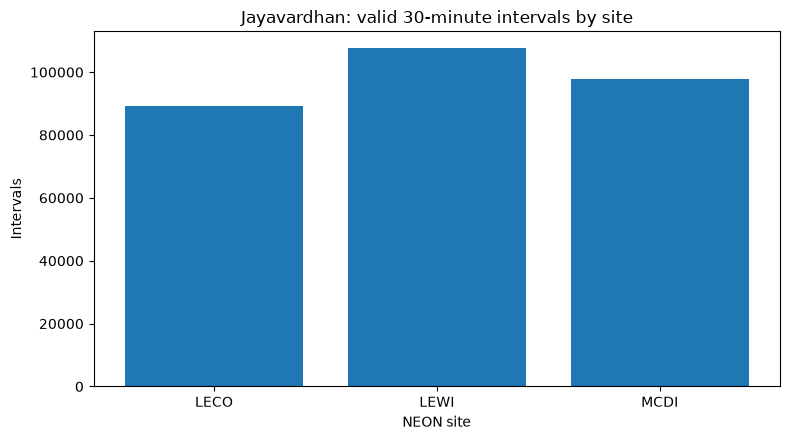

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


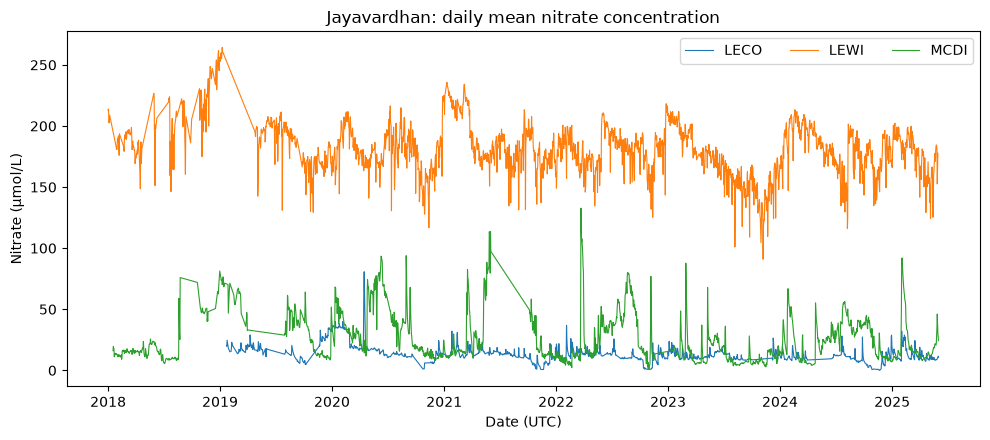

/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


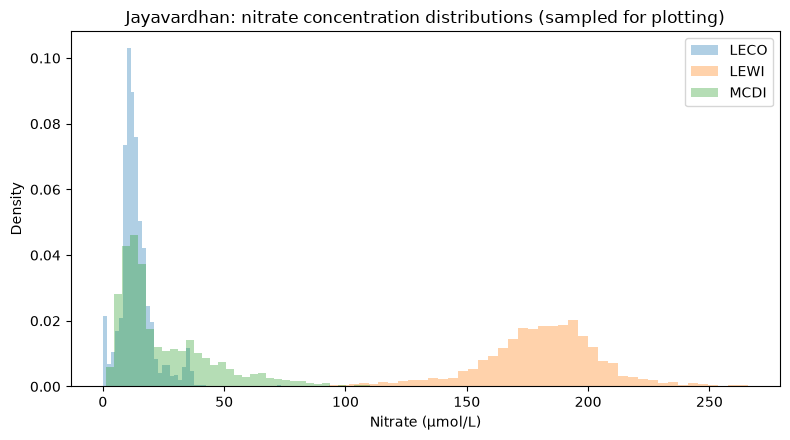

In [6]:
# Basic visualisations from the actual processed Spark dataset.
coverage_plot = site_coverage_pd.sort_values("siteID")
plt.figure(figsize=(8, 4.5))
plt.bar(coverage_plot["siteID"], coverage_plot["aggregated_30min_intervals"])
plt.title(f"{PERSON}: valid 30-minute intervals by site")
plt.xlabel("NEON site")
plt.ylabel("Intervals")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "site_coverage.png", dpi=150)
plt.show()

# Daily average plot, reduced to one row per site/day before collecting to the notebook process.
daily_pd = (
    aggregated.withColumn("date", F.to_date("time"))
    .groupBy("siteID", "date")
    .agg(F.avg("nitrate_mean").alias("daily_mean_nitrate_uM"))
    .orderBy("date")
    .toPandas()
)
plt.figure(figsize=(10, 4.5))
for site in SITE_IDS:
    d = daily_pd[daily_pd["siteID"] == site]
    plt.plot(pd.to_datetime(d["date"]), d["daily_mean_nitrate_uM"], label=site, linewidth=0.8)
plt.title(f"{PERSON}: daily mean nitrate concentration")
plt.xlabel("Date (UTC)")
plt.ylabel("Nitrate (µmol/L)")
plt.legend(ncol=3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "daily_nitrate_time_series.png", dpi=150)
plt.show()

hist_pd = aggregated.select("siteID", "nitrate_mean").sample(False, 0.04, seed=42).toPandas()
plt.figure(figsize=(8, 4.5))
for site in SITE_IDS:
    vals = hist_pd.loc[hist_pd["siteID"] == site, "nitrate_mean"].dropna()
    if len(vals):
        plt.hist(vals, bins=45, alpha=0.35, density=True, label=site)
plt.title(f"{PERSON}: nitrate concentration distributions (sampled for plotting)")
plt.xlabel("Nitrate (µmol/L)")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "nitrate_distributions.png", dpi=150)
plt.show()


## 6. Model implementation and evaluation

The three person-specific estimators are: K-Nearest Neighbors Regressor, CatBoost Regressor, XGBoost Regressor. PySpark is used for reading, quality control, aggregation, feature engineering and chronological splitting; these estimators run in the notebook Python process on a stratified sample capped per site. The evaluation metrics are MAE, RMSE and R². Persistence and seasonal-naive baselines are included. Site-level error tables are required because the selected sites have different concentration ranges.

In [7]:
# Build strict per-site chronological train/test sets for both horizons.
def make_horizon_split(frame, target_col, horizon_sql):
    labeled = (frame.filter(F.col(target_col).isNotNull())
        .withColumn("label", F.col(target_col).cast("double"))
        .withColumn("target_time", F.col("time") + F.expr(f"INTERVAL {horizon_sql}")))
    order_w = Window.partitionBy("siteID").orderBy("time")
    count_w = Window.partitionBy("siteID")
    ranked = labeled.withColumn("_rn", F.row_number().over(order_w)).withColumn("_n", F.count(F.lit(1)).over(count_w))
    cutoff = ranked.groupBy("siteID").agg(F.max(F.when(F.col("_rn") <= F.floor(F.col("_n") * F.lit(0.80)), F.col("time"))).alias("cutoff_time"))
    split = ranked.join(cutoff, on="siteID", how="inner")
    helper_cols = ["_rn", "_n", "cutoff_time", "target_time"]
    train = split.filter((F.col("time") < F.col("cutoff_time")) & (F.col("target_time") < F.col("cutoff_time"))).drop(*helper_cols)
    test = split.filter(F.col("time") >= F.col("cutoff_time")).drop(*helper_cols)
    return train, test

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings

NUMERIC_FEATURES = FEATURE_COLS
MODEL_FEATURES = NUMERIC_FEATURES + ["siteID"]
MAX_TRAIN_ROWS_PER_SITE = 1500
MAX_TEST_ROWS_PER_SITE = 2500

# The Spark DataFrame remains the source of truth for temporal splits. A bounded stratified
# sample is collected for driver-side estimators that are not all available in Spark MLlib.
def sample_by_site(frame, per_site, seed):
    sampled_parts = []
    for idx, site in enumerate(SITE_IDS):
        site_frame = frame.filter(F.col("siteID") == site)
        n_available = site_frame.count()
        if n_available > per_site:
            fraction = min(1.0, (2.0 * per_site) / float(n_available))
            piece = site_frame.sample(withReplacement=False, fraction=fraction, seed=seed + idx).limit(per_site)
        else:
            piece = site_frame
        sampled_parts.append(piece)
    out = sampled_parts[0]
    for part in sampled_parts[1:]:
        out = out.unionByName(part)
    return out

class LocalEstimatorPipeline:
    """Small adapter so any compatible estimator can use the common preprocessing."""
    def __init__(self, estimator):
        self.preprocessor = ColumnTransformer([
            ("numeric", SklearnPipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUMERIC_FEATURES),
            ("site", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["siteID"]),
        ], remainder="drop", sparse_threshold=0.0)
        self.estimator = estimator
    def fit(self, X, y):
        X_transformed = self.preprocessor.fit_transform(X)
        self.estimator.fit(X_transformed, y)
        return self
    def predict(self, X):
        return self.estimator.predict(self.preprocessor.transform(X))

def make_sklearn_pipeline(estimator):
    return LocalEstimatorPipeline(estimator)

def calculate_metrics(y_true, y_pred):
    return {"MAE": float(mean_absolute_error(y_true, y_pred)),
            "RMSE": float(mean_squared_error(y_true, y_pred) ** 0.5),
            "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 and float(pd.Series(y_true).var()) > 0 else float("nan")}

def make_person_model_specs():
    return [
    ("K-Nearest Neighbors Regressor", lambda: KNeighborsRegressor(n_neighbors=15, weights="distance", p=2, n_jobs=-1)),
    ("CatBoost Regressor", lambda: CatBoostRegressor(iterations=120, depth=6, learning_rate=0.05, loss_function="RMSE", verbose=False, allow_writing_files=False, random_seed=42, thread_count=1)),
    ("XGBoost Regressor", lambda: XGBRegressor(n_estimators=120, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, objective="reg:squarederror", tree_method="hist", n_jobs=1, random_state=42, verbosity=0)),
]

MODEL_SPECS = make_person_model_specs()
MODEL_NAMES = [name for name, _ in MODEL_SPECS]
SCALING_MODEL_NAME = "XGBoost Regressor"

model_rows = []
site_model_rows = []
scaling_train_pd_24 = None
scaling_test_pd_24 = None

for horizon, target_col, horizon_sql, seasonal_col in [
    ("24h", "target_24h", "1 DAY", "lag_24h"),
    ("7d", "target_7d", "7 DAYS", "lag_7d"),
]:
    train, test = make_horizon_split(features_df, target_col, horizon_sql)
    train_total, test_total = train.count(), test.count()
    sampled_train = sample_by_site(train, MAX_TRAIN_ROWS_PER_SITE, seed=42)
    sampled_test = sample_by_site(test, MAX_TEST_ROWS_PER_SITE, seed=142)
    train_pd = sampled_train.select("siteID", "time", "label", *NUMERIC_FEATURES).toPandas()
    test_pd = sampled_test.select("siteID", "time", "label", *NUMERIC_FEATURES).toPandas()
    if horizon == "24h":
        scaling_train_pd_24 = train_pd.copy()
        scaling_test_pd_24 = test_pd.copy()
    print(f"\nHorizon={horizon}; Spark train rows={train_total:,}; Spark test rows={test_total:,}; estimator training sample={len(train_pd):,}; evaluation sample={len(test_pd):,}")
    X_train, y_train = train_pd[MODEL_FEATURES], train_pd["label"].to_numpy()
    X_test, y_test = test_pd[MODEL_FEATURES], test_pd["label"].to_numpy()

    for model_name, model_factory in MODEL_SPECS:
        pipeline = make_sklearn_pipeline(model_factory())
        t0 = time.perf_counter()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            pipeline.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - t0
        t0 = time.perf_counter()
        predictions = pipeline.predict(X_test)
        predict_seconds = time.perf_counter() - t0
        overall = calculate_metrics(y_test, predictions)
        model_rows.append({"horizon": horizon, "model": model_name,
            "spark_train_rows": int(train_total), "spark_test_rows": int(test_total),
            "n_train_used": int(len(train_pd)), "n_test_evaluated": int(len(test_pd)),
            "fit_seconds_driver_estimator": fit_seconds, "predict_seconds_driver_estimator": predict_seconds,
            **overall})
        scored = test_pd[["siteID", "label"]].copy()
        scored["prediction"] = predictions
        for site in SITE_IDS:
            part = scored[scored.siteID == site]
            if len(part):
                site_metrics = calculate_metrics(part.label.to_numpy(), part.prediction.to_numpy())
                site_model_rows.append({"siteID": site, "horizon": horizon, "model": model_name,
                    "n_test": int(len(part)), **site_metrics})
        print(f"{model_name}: RMSE={overall['RMSE']:.4f}; MAE={overall['MAE']:.4f}; R2={overall['R2']:.4f}; fit={fit_seconds:.2f}s; predict={predict_seconds:.2f}s")

    # Naive baselines use exactly the same sampled holdout rows where each predictor exists.
    for baseline_name, baseline_col in [("Persistence (current value)", "nitrate_mean"), ("Seasonal naive (matching lag)", seasonal_col)]:
        baseline_pd = sampled_test.select("siteID", "label", baseline_col).toPandas().dropna(subset=[baseline_col])
        if baseline_pd.empty:
            continue
        pred = baseline_pd[baseline_col].to_numpy()
        overall = calculate_metrics(baseline_pd.label.to_numpy(), pred)
        model_rows.append({"horizon": horizon, "model": baseline_name,
            "spark_train_rows": int(train_total), "spark_test_rows": int(test_total),
            "n_train_used": int(len(train_pd)), "n_test_evaluated": int(len(baseline_pd)),
            "fit_seconds_driver_estimator": 0.0, "predict_seconds_driver_estimator": 0.0, **overall})
        for site in SITE_IDS:
            part = baseline_pd[baseline_pd.siteID == site]
            if len(part):
                bm = calculate_metrics(part.label.to_numpy(), part[baseline_col].to_numpy())
                site_model_rows.append({"siteID": site, "horizon": horizon, "model": baseline_name,
                    "n_test": int(len(part)), **bm})
        print(f"{baseline_name}: RMSE={overall['RMSE']:.4f}; MAE={overall['MAE']:.4f}; R2={overall['R2']:.4f}")

metrics_pd = pd.DataFrame(model_rows)
site_metrics_pd = pd.DataFrame(site_model_rows)
metrics_pd.to_csv(TABLE_DIR / "model_metrics_personal_models.csv", index=False)
site_metrics_pd.to_csv(TABLE_DIR / "site_model_metrics_personal_models.csv", index=False)
display(metrics_pd.sort_values(["horizon", "RMSE"]))
display(site_metrics_pd.sort_values(["siteID", "horizon", "RMSE"]))


/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet


Horizon=24h; Spark train rows=227,569; Spark test rows=56,934; estimator training sample=4,500; evaluation sample=7,500
K-Nearest Neighbors Regressor: RMSE=13.5638; MAE=8.1589; R2=0.9693; fit=0.04s; predict=0.16s
CatBoost Regressor: RMSE=11.8729; MAE=6.2129; R2=0.9765; fit=0.31s; predict=0.01s
XGBoost Regressor: RMSE=11.9933; MAE=6.1751; R2=0.9760; fit=1.80s; predict=0.02s


/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Persistence (current value): RMSE=14.0341; MAE=6.4997; R2=0.9671


/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


...

Persistence (current value): RMSE=17.4488; MAE=9.7567; R2=0.9482


/home/vishnu/miniconda3/envs/spark/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Seasonal naive (matching lag): RMSE=19.5170; MAE=11.6332; R2=0.9359


,horizon,model,spark_train_rows,spark_test_rows,n_train_used,n_test_evaluated,fit_seconds_driver_estimator,predict_seconds_driver_estimator,MAE,RMSE,R2
1,24h,CatBoost Regressor,227569,56934,4500,7500,0.307844,0.008044,6.212883,11.872935,0.976455
2,24h,XGBoost Regressor,227569,56934,4500,7500,1.799335,0.016201,6.175094,11.993272,0.975976
0,24h,K-Nearest Neighbors Regressor,227569,56934,4500,7500,0.039481,0.160582,8.158874,13.563801,0.969272
3,24h,Persistence (current value),227569,56934,4500,7500,0.000000,0.000000,6.499747,14.034138,0.967104
4,24h,Seasonal naive (matching lag),227569,56934,4500,7337,0.000000,0.000000,7.598985,15.150490,0.961583
6,7d,CatBoost Regressor,216255,54266,4500,7500,0.255464,0.007508,8.839901,14.563403,0.963948
7,7d,XGBoost Regressor,216255,54266,4500,7500,0.156940,0.015771,9.516943,15.259838,0.960418
5,7d,K-Nearest Neighbors Regressor,216255,54266,4500,7500,0.014820,0.060809,10.046498,16.096750,0.955957
8,7d,Persistence (current value),216255,54266,4500,7500,0.000000,0.000000,9.756700,17.448766,0.948248
9,7d,Seasonal naive (matching lag),216255,54266,4500,7081,0.000000,0.000000,11.633202,19.516953,0.935934


,siteID,horizon,model,n_test,MAE,RMSE,R2
9,LECO,24h,Persistence (current value),2500,1.643560,3.652599,0.550853
6,LECO,24h,XGBoost Regressor,2500,2.179512,3.667305,0.547229
3,LECO,24h,CatBoost Regressor,2500,2.359858,3.785015,0.517698
12,LECO,24h,Seasonal naive (matching lag),2444,2.361129,4.482583,0.330455
0,LECO,24h,K-Nearest Neighbors Regressor,2500,3.494584,4.600549,0.287470
15,LECO,7d,K-Nearest Neighbors Regressor,2500,3.970034,5.086902,0.137417
18,LECO,7d,CatBoost Regressor,2500,4.118832,5.397344,0.028922
24,LECO,7d,Persistence (current value),2500,3.534160,5.492257,-0.005532
27,LECO,7d,Seasonal naive (matching lag),2278,4.397432,6.790354,-0.468572
21,LECO,7d,XGBoost Regressor,2500,4.604198,6.832101,-0.555975


## 7. Execution-time and scalability analysis

The notebook measures fit/predict wall-clock seconds for the assigned estimator at 25%, 50% and 100% of the bounded training sample. Spark handles the data pipeline; the selected Python estimators execute in the notebook process. Report these timings as local estimator timings, not Spark MLlib timings.

25%: train=1,125; fit=0.12s; predict=0.01s
50%: train=2,250; fit=0.13s; predict=0.01s
100%: train=4,500; fit=0.15s; predict=0.01s


,training_fraction,training_rows,scoring_rows,fit_seconds,predict_seconds,model
0,0.25,1125,3000,0.116619,0.010395,XGBoost Regressor
1,0.50,2250,3000,0.128768,0.010696,XGBoost Regressor
2,1.00,4500,3000,0.152265,0.010566,XGBoost Regressor


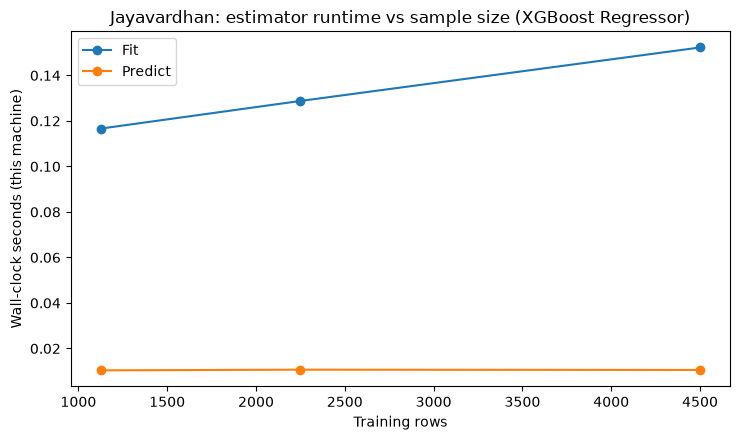

In [8]:
# Sample-size scaling experiment for the primary algorithm assigned to this person.
# This measures estimator fit/predict time on the Spark-selected sample; Spark preprocessing is
# distributed above, while these particular estimators execute in the notebook Python process.
from sklearn.base import clone
scaling_rows = []
scaling_train = scaling_train_pd_24.copy()
scoring_pd = scaling_test_pd_24.head(min(3000, len(scaling_test_pd_24))).copy()
scaling_factory = dict(MODEL_SPECS)[SCALING_MODEL_NAME]
for frac in [0.25, 0.50, 1.00]:
    n = max(30, min(len(scaling_train), int(round(len(scaling_train) * frac))))
    part = scaling_train.sample(n=n, random_state=400 + int(frac * 100)) if n < len(scaling_train) else scaling_train
    pipeline = make_sklearn_pipeline(scaling_factory())
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipeline.fit(part[MODEL_FEATURES], part["label"])
    fit_seconds = time.perf_counter() - t0
    t0 = time.perf_counter()
    _ = pipeline.predict(scoring_pd[MODEL_FEATURES])
    predict_seconds = time.perf_counter() - t0
    scaling_rows.append({"training_fraction": frac, "training_rows": len(part), "scoring_rows": len(scoring_pd),
                         "fit_seconds": fit_seconds, "predict_seconds": predict_seconds,
                         "model": SCALING_MODEL_NAME})
    print(f"{frac:.0%}: train={len(part):,}; fit={fit_seconds:.2f}s; predict={predict_seconds:.2f}s")
scaling_pd = pd.DataFrame(scaling_rows)
scaling_pd.to_csv(TABLE_DIR / "scalability_results_personal_models.csv", index=False)
display(scaling_pd)
plt.figure(figsize=(7.5, 4.5))
plt.plot(scaling_pd["training_rows"], scaling_pd["fit_seconds"], marker="o", label="Fit")
plt.plot(scaling_pd["training_rows"], scaling_pd["predict_seconds"], marker="o", label="Predict")
plt.title(f"{PERSON}: estimator runtime vs sample size ({SCALING_MODEL_NAME})")
plt.xlabel("Training rows"); plt.ylabel("Wall-clock seconds (this machine)")
plt.legend(); plt.tight_layout(); plt.savefig(FIGURE_DIR / "runtime_scalability_personal_models.png", dpi=150); plt.show()


## 8. Outputs, interpretation and references

The notebook writes CSV tables and PNG figures to `outputs/`. Cite the official NEON product, PySpark, scikit-learn, and the model-library documentation. Treat pooled R² cautiously and discuss site-level errors and long-horizon uncertainty.

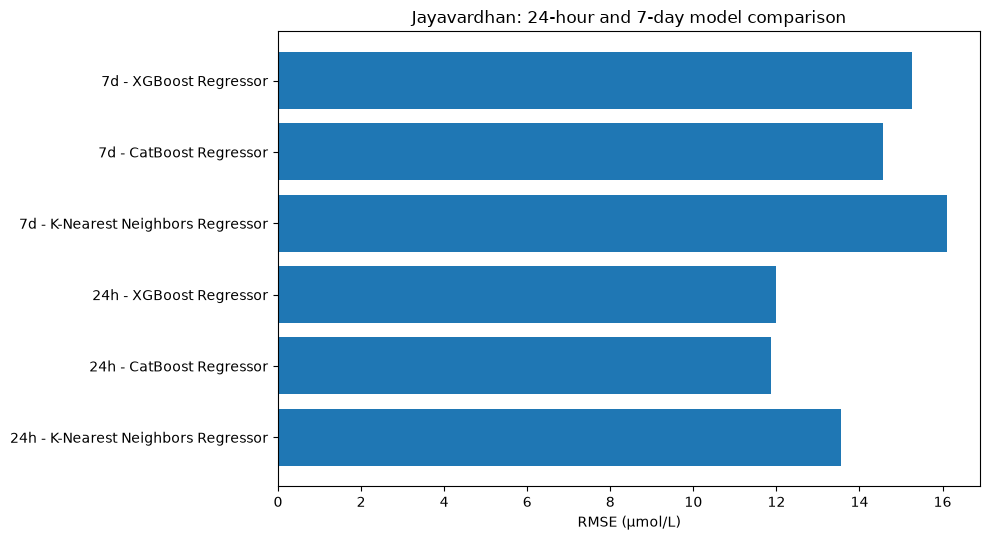

Outputs saved to: /home/vishnu/Downloads/BDA_LA2/person3_updated_LA2/outputs
Model metrics:  /home/vishnu/Downloads/BDA_LA2/person3_updated_LA2/outputs/tables/model_metrics_personal_models.csv
Site-level metrics:  /home/vishnu/Downloads/BDA_LA2/person3_updated_LA2/outputs/tables/site_model_metrics_personal_models.csv
Scalability metrics:  /home/vishnu/Downloads/BDA_LA2/person3_updated_LA2/outputs/tables/scalability_results_personal_models.csv
No model uses future target values as predictors. Read the final report's sampling note before interpreting model comparisons.


In [9]:
# Comparison plot from this notebook's own model results.
ml_metrics = metrics_pd[metrics_pd["model"].isin(MODEL_NAMES)].copy()
ml_metrics["label"] = ml_metrics["horizon"] + " - " + ml_metrics["model"]
plt.figure(figsize=(10, max(5.5, 0.36 * len(ml_metrics))))
plt.barh(ml_metrics["label"], ml_metrics["RMSE"])
plt.xlabel("RMSE (µmol/L)")
plt.title(f"{PERSON}: 24-hour and 7-day model comparison")
plt.tight_layout(); plt.savefig(FIGURE_DIR / "model_rmse_comparison_personal_models.png", dpi=150); plt.show()
print("Outputs saved to:", OUTPUT_DIR)
print("Model metrics: ", TABLE_DIR / "model_metrics_personal_models.csv")
print("Site-level metrics: ", TABLE_DIR / "site_model_metrics_personal_models.csv")
print("Scalability metrics: ", TABLE_DIR / "scalability_results_personal_models.csv")
print("No model uses future target values as predictors. Read the final report's sampling note before interpreting model comparisons.")
